# GLM-HMM and DDM prior effects against tremor dominance

Continuous counterpart of the subtype comparisons in `notebooks/4.20-occupancy-weighted-and-convergence`
(GLM-HMM) and `notebooks/3.40-ddm-fit-subtypes` (DDM). There, each model's per-session prior effect was
compared OFF versus ON within tremor-dominant and bradykinesia-dominant groups. Here the same
per-session quantities are correlated with the continuous OFF-medication score across all 22 patients
who have it.

| Model | Per-session prior effect | Source |
|---|---|---|
| GLM-HMM | occupancy-weighted colour weight, sum_k occupancy_k x w_colour,k (log-odds) | recomputed exactly as in `notebooks/4.20` |
| DDM | drift-rate offset, Positive-Prior minus Equal-Prior (primary, as in `notebooks/4.20`) | `processed_metadata_all_data_accu_60_ddm_params.csv` |
| DDM | starting point z, Positive-Prior minus Equal-Prior (secondary) | same file |
| Model-free | P(positive choice) at 0% coherence, Positive-Prior minus Equal-Prior | trial data |

For each: the OFF prior effect, the ON prior effect and the OFF-to-ON change, each against the score.
Spearman rho, 20,000-permutation p-values, bootstrap intervals over patients.

Reads the fitted GLM-HMM bundle and DDM parameters from the data directory (read only). Writes only to
`outputs/notebooks_2/`.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
import pickle

from scipy.optimize import linear_sum_assignment

from config import dir_config, main_config
from src.shared_glm_hmm.fitting import session_arrays
from src.utils.motor_score import OUTPUT_DIR, SCORE, correlate, leave_one_out_rho, motor_scores

processed_dir = Path(dir_config.data.processed)
metadata = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60.csv", encoding="latin1")
ddm_params = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60_ddm_params.csv", encoding="latin1")
filtered_data = pd.read_csv(processed_dir / "processed_all_data_accu_60_filtered.csv", index_col=None)
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scores = motor_scores(metadata)
CATEGORY_COLOR = {"tremor": "#B5541D", "bradykinetic": "#4A5A6B", "intermediate": "#9A9A9A"}

bundle = pickle.load(open(processed_dir / "shared_glm_hmm" / main_config.GLM_HMM.final_model / "all_subjects_final.pkl", "rb"))
features = bundle["config"]["model_features"]
COLOUR = features.index("color")
print(f"GLM-HMM {main_config.GLM_HMM.final_model}, K = {bundle['best_k']}")

GLM-HMM XY__tgt, K = 4


## Per-session prior effects

GLM-HMM: weights sign-flipped to the log-odds of a positive choice, states Hungarian-aligned to the
pooled reference, occupancy from the posterior state probabilities, all as in `notebooks/4.20`.

In [3]:
def align(weights, reference):
    cost = ((weights[:, None, :] - reference[None, :, :]) ** 2).sum(-1)
    _, col = linear_sum_assignment(cost)
    inverse = np.empty_like(col)
    inverse[col] = np.arange(len(col))
    return inverse


reference = -bundle["model"]["pooled"].observations.params[:, 0, :]
observations, inputs, masks = session_arrays(bundle)
hmm_rows = []
for i, session in enumerate(bundle["data"].keys()):
    model = bundle["model"]["models"][session]
    weights = -model.observations.params[:, 0, :]
    order = align(weights, reference)
    posterior = model.expected_states(data=observations[i], input=inputs[i], mask=masks[i])[0]
    occupancy = posterior[:, order][masks[i][:, 0]].mean(0)
    hmm_rows.append({"session_id": session, "glm_hmm": float(occupancy @ weights[order][:, COLOUR])})

session_keys = metadata[["session_id", "subject_id", "treatment"]].dropna()
hmm = pd.DataFrame(hmm_rows).merge(session_keys, on="session_id", how="left")

ddm = ddm_params.dropna(subset=["treatment"]).copy()
ddm["ddm_drift_offset"] = ddm["drift_offset_prior_cond_1"].astype(float) - ddm["drift_offset_prior_cond_0"].astype(float)
ddm["ddm_start_point"] = ddm["z_prior_cond_1"].astype(float) - ddm["z_prior_cond_0"].astype(float)

zero = filtered_data[filtered_data["coherence"] == 0].groupby(["subject_id", "medication", "color"])["choice"].mean().unstack("color")
model_free = (zero[1] - zero[0]).rename("model_free").reset_index()
model_free["treatment"] = model_free["medication"].str.upper()

MEASURES = {"glm_hmm": "GLM-HMM occupancy-weighted colour weight",
            "ddm_drift_offset": "DDM drift-rate offset",
            "ddm_start_point": "DDM starting point",
            "model_free": "model-free, P(positive) at 0% coherence"}

long = pd.concat([
    hmm.rename(columns={"glm_hmm": "value"}).assign(measure="glm_hmm"),
    ddm[["subject_id", "treatment", "ddm_drift_offset"]].rename(columns={"ddm_drift_offset": "value"}).assign(measure="ddm_drift_offset"),
    ddm[["subject_id", "treatment", "ddm_start_point"]].rename(columns={"ddm_start_point": "value"}).assign(measure="ddm_start_point"),
    model_free[["subject_id", "treatment", "model_free"]].rename(columns={"model_free": "value"}).assign(measure="model_free"),
])[["subject_id", "treatment", "measure", "value"]]
long = long[long["subject_id"].isin(scores.index) & long["treatment"].isin(["OFF", "ON"])]

per_patient = long.pivot_table(index="subject_id", columns=["measure", "treatment"], values="value")
for measure in MEASURES:
    per_patient[(measure, "change")] = per_patient[(measure, "ON")] - per_patient[(measure, "OFF")]
per_patient = per_patient.sort_index(axis=1).reindex(scores.index)
print({m: int(per_patient[(m, "change")].notna().sum()) for m in MEASURES}, "patients with an OFF-to-ON change, per measure")
per_patient.round(3)

{'glm_hmm': 22, 'ddm_drift_offset': 22, 'ddm_start_point': 22, 'model_free': 22} patients with an OFF-to-ON change, per measure


measure    ddm_drift_offset               ddm_start_point                \
treatment               OFF     ON change             OFF     ON change   
subject_id                                                                
P22                  -0.117 -1.054 -0.937           0.126  0.097 -0.029   
P23                   1.345  0.901 -0.443          -0.053 -0.018  0.035   
P1                   -0.222  1.222  1.444           0.076 -0.051 -0.128   
P33                   0.291  0.407  0.116          -0.018 -0.013  0.005   
P20                  -0.135  0.241  0.376          -0.008 -0.004  0.004   
P28                   0.024  0.483  0.459           0.026  0.062  0.037   
P13                   0.193  0.449  0.256           0.016 -0.031 -0.048   
P9                   -0.300  0.240  0.540          -0.005 -0.102 -0.097   
P34                  -0.474  0.113  0.587           0.034  0.041  0.007   
P4                    0.547 -0.351 -0.897          -0.068  0.029  0.097   
P24                   0.895 -0.326 -1.221          -0.007  0.001  0.009   
P17                   0.238  1.702  1.464           0.037 -0.041 -0.078   
P6                   -1.184  1.740  2.924          -0.019 -0.048 -0.029   
P29                  -0.110  0.445  0.555           0.041  0.049  0.009   
P18                   0.613  0.423 -0.190           0.029 -0.007 -0.035   
P19                  -0.138 -0.137  0.001           0.007  0.077  0.070   
P11                  -0.044 -0.176 -0.132          -0.041  0.097  0.138   
P32                   0.216  1.026  0.810          -0.010 -0.067 -0.056   
P3                   -0.351  0.513  0.864           0.029 -0.029 -0.058   
P7                    0.117 -0.306 -0.423          -0.040 -0.009  0.031   
P12                   0.139  0.386  0.247          -0.065  0.021  0.086   
P31                   0.622  0.031 -0.591           0.014  0.022  0.008   

measure    glm_hmm               model_free                
treatment      OFF     ON change        OFF     ON change  
subject_id                                                 
P22          0.580 -0.819 -1.398      0.162 -0.188 -0.350  
P23          1.521  0.688 -0.833      0.443  0.102 -0.341  
P1          -0.322  1.045  1.367     -0.020  0.324  0.343  
P33          0.563  0.441 -0.122      0.132  0.070 -0.062  
P20          0.075  0.220  0.145     -0.012  0.132  0.144  
P28          0.201  1.100  0.899      0.034  0.177  0.143  
P13          0.265 -0.068 -0.333      0.026 -0.056 -0.082  
P9          -0.660  0.078  0.738     -0.087 -0.043  0.045  
P34         -0.237  0.094  0.331     -0.051  0.050  0.101  
P4           0.257 -0.406 -0.663      0.059 -0.094 -0.152  
P24          1.537 -0.378 -1.915      0.504 -0.031 -0.536  
P17          0.085  2.109  2.024      0.007  0.288  0.281  
P6          -1.009  0.908  1.917     -0.266  0.100  0.366  
P29         -0.674  1.024  1.699     -0.112  0.158  0.271  
P18          1.025  1.018 -0.007      0.262  0.250 -0.012  
P19         -0.183  0.050  0.234     -0.126  0.043  0.169  
P11         -0.063  0.315  0.378      0.020 -0.006 -0.025  
P32          0.431  0.560  0.130      0.070  0.200  0.130  
P3          -0.406  0.260  0.666     -0.094  0.054  0.148  
P7           0.538 -0.193 -0.732      0.006 -0.040 -0.046  
P12         -0.279  0.903  1.182     -0.102  0.177  0.279  
P31          1.227  0.191 -1.036      0.343  0.013 -0.330

## Correlations with the score

In [4]:
rows = []
for measure in MEASURES:
    for state in ["OFF", "ON", "change"]:
        rows.append({"measure": measure, "prior effect": state, **correlate(scores[SCORE], per_patient[(measure, state)])})
correlations = pd.DataFrame(rows).set_index(["measure", "prior effect"])
correlations.round(3)

n  spearman rho  rho 2.5%  rho 97.5%  \
measure          prior effect                                          
glm_hmm          OFF           22        -0.132    -0.549      0.344   
                 ON            22         0.024    -0.416      0.444   
                 change        22         0.116    -0.378      0.535   
ddm_drift_offset OFF           22         0.054    -0.385      0.480   
                 ON            22        -0.086    -0.529      0.355   
                 change        22         0.023    -0.437      0.449   
ddm_start_point  OFF           22        -0.233    -0.650      0.243   
                 ON            22         0.077    -0.349      0.497   
                 change        22         0.215    -0.219      0.599   
model_free       OFF           22        -0.248    -0.632      0.207   
                 ON            22         0.042    -0.425      0.485   
                 change        22         0.209    -0.305      0.604   

                               p (perm, rho)  pearson r  p (perm, r)  
measure          prior effect                                         
glm_hmm          OFF                   0.558     -0.097        0.664  
                 ON                    0.916      0.122        0.593  
                 change                0.608      0.138        0.542  
ddm_drift_offset OFF                   0.811     -0.038        0.862  
                 ON                    0.703      0.028        0.898  
                 change                0.919      0.042        0.858  
ddm_start_point  OFF                   0.289     -0.379        0.083  
                 ON                    0.731     -0.010        0.965  
                 change                0.328      0.260        0.238  
model_free       OFF                   0.265     -0.155        0.485  
                 ON                    0.853      0.085        0.712  
                 change                0.348      0.165        0.468

### Do the models agree about which patients change?

The categorical notebook showed the three models rank participants' OFF-to-ON changes almost
identically (Spearman around 0.8 to 0.98). If that holds here too, a weak correlation with the
score is not a measurement problem in any one model: the patients' changes are well measured, they
just do not line up with tremor dominance.

In [5]:
changes = per_patient.xs("change", axis=1, level=1)
changes.corr(method="spearman").round(3)

measure,ddm_drift_offset,ddm_start_point,glm_hmm,model_free
measure,,,,
ddm_drift_offset,1.000,-0.584,0.849,0.842
ddm_start_point,-0.584,1.000,-0.257,-0.283
glm_hmm,0.849,-0.257,1.000,0.921
model_free,0.842,-0.283,0.921,1.000


### Figure. OFF-to-ON change in prior effect against the score

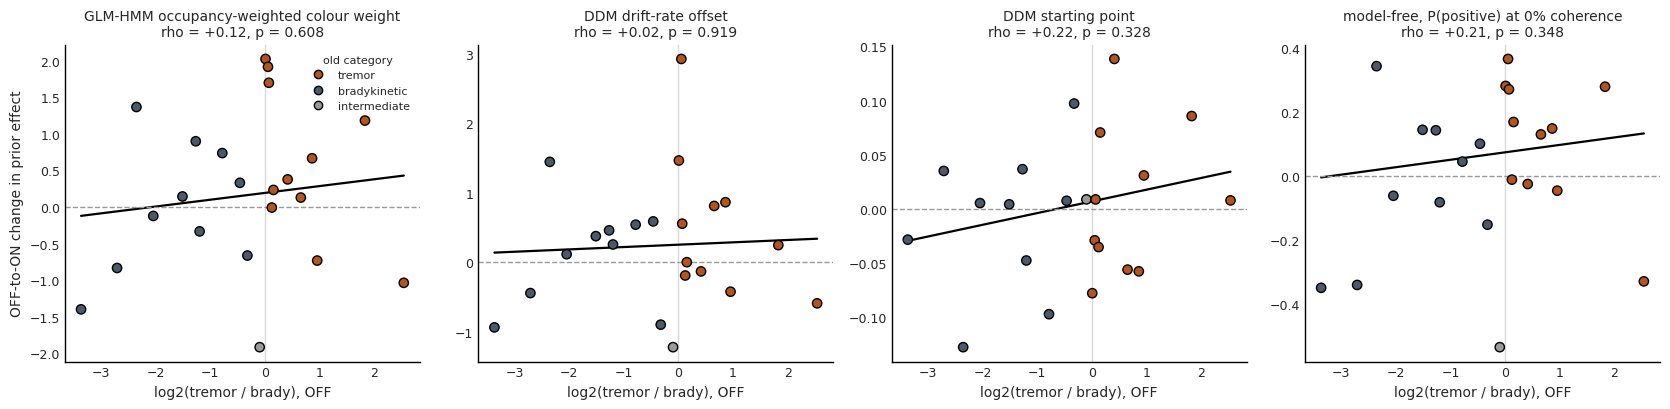

In [6]:
fig, axes = plt.subplots(1, len(MEASURES), figsize=(4.2 * len(MEASURES), 4.2), sharex=True)
for ax, (measure, label) in zip(axes, MEASURES.items()):
    y = per_patient[(measure, "change")]
    ax.scatter(scores[SCORE], y, c=scores["category"].map(CATEGORY_COLOR), s=45, edgecolor="k", zorder=3)
    ok = y.notna()
    slope, intercept, _, _ = stats.theilslopes(y[ok], scores.loc[ok, SCORE])
    grid = np.linspace(scores[SCORE].min(), scores[SCORE].max(), 50)
    ax.plot(grid, intercept + slope * grid, color="k", lw=1.6)
    ax.axhline(0, color="0.6", ls="--", lw=1)
    ax.axvline(0, color="0.85", lw=1, zorder=0)
    r = correlations.loc[(measure, "change")]
    ax.set_title(f"{label}\nrho = {r['spearman rho']:+.2f}, p = {r['p (perm, rho)']:.3f}", fontsize=10)
    ax.set_xlabel("log2(tremor / brady), OFF", fontsize=10)
    ax.tick_params(labelsize=9)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("OFF-to-ON change in prior effect", fontsize=10)
handles = [plt.Line2D([], [], ls="", marker="o", mec="k", color=c, label=k) for k, c in CATEGORY_COLOR.items()]
axes[0].legend(handles=handles, frameon=False, fontsize=8, title="old category", title_fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "glm_hmm_ddm_vs_score.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "glm_hmm_ddm_vs_score.png", dpi=200, bbox_inches="tight")
plt.show()

### Influential patients, GLM-HMM change

In [7]:
influence = leave_one_out_rho(scores[SCORE], per_patient[("glm_hmm", "change")], scores.index)
print(f"leave-one-out rho range {influence['rho'].min():+.3f} to {influence['rho'].max():+.3f}")
influence.round(3).T

leave-one-out rho range -0.004 to +0.242


dropped,P22,P23,P12,P33,P13,P20,P24,P29,P6,P17,P4,P3,P11,P34,P19,P18,P9,P32,P28,P1,P7,P31
rho,-0.004,0.022,0.062,0.073,0.088,0.103,0.104,0.104,0.104,0.104,0.108,0.109,0.114,0.118,0.123,0.134,0.142,0.142,0.153,0.195,0.200,0.242
shift,-0.120,-0.094,-0.053,-0.043,-0.027,-0.013,-0.012,-0.012,-0.012,-0.012,-0.008,-0.007,-0.001,0.002,0.008,0.018,0.026,0.026,0.037,0.079,0.084,0.126


### For comparison: the categorical contrast on the same numbers

In [8]:
category_rows = []
for measure in MEASURES:
    change = per_patient[(measure, "change")]
    tremor, brady = change[scores["category"] == "tremor"].dropna(), change[scores["category"] == "bradykinetic"].dropna()
    category_rows.append({"measure": measure, "tremor mean": tremor.mean(), "brady mean": brady.mean(),
                          "Mann-Whitney p (tremor vs brady)": stats.mannwhitneyu(tremor, brady).pvalue,
                          "Spearman rho (score, all 22)": correlations.loc[(measure, "change"), "spearman rho"],
                          "permutation p (score)": correlations.loc[(measure, "change"), "p (perm, rho)"]})
pd.DataFrame(category_rows).set_index("measure").round(3)

,tremor mean,brady mean,Mann-Whitney p (tremor vs brady),"Spearman rho (score, all 22)",permutation p (score)
measure,,,,,
glm_hmm,0.587,0.013,0.245,0.116,0.608
ddm_drift_offset,0.503,0.150,0.549,0.023,0.919
ddm_start_point,0.008,-0.012,0.699,0.215,0.328
model_free,0.112,-0.021,0.098,0.209,0.348


In [9]:
per_patient.columns = [f"{m} {s}" for m, s in per_patient.columns]
per_patient.join(scores[[SCORE, "category"]]).to_csv(OUTPUT_DIR / "glm_hmm_ddm_prior_effects_by_patient.csv")
correlations.to_csv(OUTPUT_DIR / "glm_hmm_ddm_vs_score.csv")
print("wrote glm_hmm_ddm_* tables and figure to", OUTPUT_DIR.relative_to(OUTPUT_DIR.parents[1]))

wrote glm_hmm_ddm_* tables and figure to outputs/notebooks_2


## Results

Values are from this run.

**No model's OFF-to-ON change in prior effect tracks the score.**

| Measure | rho with score | permutation p | categorical Mann-Whitney p |
|---|---|---|---|
| GLM-HMM occupancy-weighted colour weight | +0.12 | 0.61 | 0.25 |
| DDM drift-rate offset | +0.02 | 0.92 | 0.55 |
| DDM starting point (secondary) | +0.22 | 0.33 | 0.70 |
| model-free, 0% coherence | +0.21 | 0.35 | 0.10 |

None of the OFF or ON prior effects correlates with the score either (all |rho| <= 0.25).

**This is not a measurement problem.** The GLM-HMM, the DDM drift offset and the model-free measure
rank the patients' OFF-to-ON changes almost identically (Spearman 0.84 to 0.92 across all 22 patients),
as in `notebooks/4.20`. The patients' changes are well measured and consistent across models; they do
not line up with tremor dominance. The DDM starting-point shift is not in that cluster (-0.26 to -0.58
with the others), which is why the drift offset is the primary DDM quantity, as in `notebooks/4.20`.

**Same pattern as the mixed model.** In every panel the largest positive changes (P6, P17, P29) are
just above the ratio-1 cut-off. P24, just below it, has the largest negative GLM-HMM change (-1.9), and
P31 at the tremor-dominant extreme is negative. The GLM-HMM correlation ranges from -0.00 (without P22)
to +0.24 (without P31) when one patient is left out.